
# 09 期权投资盈利之道：核心笔记

> **本章要解决的问题**：期权为什么“看起来简单、做起来难”？买 call/put 和卖 call/put 到底赚的是什么钱？为什么同一套策略，有人长期稳定、有人一次爆仓？权益多头加期权，风险敞口该怎么算？

## 本章导读

这一章是沈发鹏《期权投资盈利之道：期权策略的“体系化”运用，权益配合的“方法论”实践》的零基础笔记。原书的主线很清楚：**期权不是“赌方向”的工具，而是一套可以体系化管理的风险工具**——先把基础、风险、策略搞清楚，再谈进阶的波动率交易，最后落到“期权配套权益多头”的整体观。

本笔记按原书结构分四块：

1. **入门**：call/put、内在价值/时间价值、Greeks、IV；风险管理（仓位、保证金、压力测试、最大损失）；六类基础策略（covered call、protective put、牛市/熊市价差、跨式/宽跨式、领口、比率）；
2. **进阶**：波动率的计算与预测；中性卖方/买方；波动率曲面交易；基差交易；
3. **升华**：投资观、期权工具化配套权益指数多头、期权投资整体观；
4. **国内期权背景与一人量化用法**：ETF/指数期权、合约单位、行权、保证金、流动性、到期日（教学示例，以交易所最新规则为准），以及“先画 payoff 与风险图，再谈方向”的落地方法。

> **重要说明**：本笔记所有标的价格、波动率、权利金、保证金比例都是**合成教学数据**，只用于演示方法，不能直接拿去交易。涉及国内交易所的合约单位、行权方式、保证金、到期日等参数，均为**教学示例，以交易所最新规则为准**，不构成投资建议。

### 学习目标

- 能用一句话说清 call 与 put 的买方/卖方各自的权利、义务、最大盈利与最大亏损。
- 能把期权价格拆成内在价值 + 时间价值，并解释 IV 与时间价值的关系。
- 能写出 Delta/Gamma/Vega/Theta 的含义，并说明买方与卖方的符号为什么相反。
- 能画出 covered call、protective put、牛市价差、跨式、领口、比率六类策略的到期 payoff，标出最大盈亏与盈亏平衡点。
- 能对一个期权组合做“标的价格 × IV × 时间”的情景 PnL，并指出 Gamma/Vega/Theta 各贡献了什么。
- 能把权益现货与期权放在同一个组合里，算整体 Delta/Vega 敞口，并说清“保护”或“增强”的代价。

### 先修

会基础统计（平均、标准差）；会一点 Python（numpy/pandas）；不需要期权账户或交易经验。第 24–28 章可以配合阅读（BSM、Greeks、价差、对冲）。

---

## 在量化研究中的位置

- **谁用**：期权交易员、权益+期权策略研究者、一人量化、做增强/保护的资产管理者。
- **输入**：标的价格与波动率、期权链报价、合约规则、账户资金与风险预算。
- **输出**：策略 payoff/风险图、Greeks 敞口、情景 PnL、保证金与仓位、组合整体敞口。
- **在流程的哪一步**：在“有观点”之后、“下单之前”；它把观点翻译成“可以承受的风险结构”。
- **失败模式**：只看方向不看 IV、卖方只算权利金不算尾部、买方忽略 theta、把权益和期权分成两个账户各算各的。
- **最小工作流**：写观点 → 画 payoff/风险图 → 算 Greeks 与最大损失 → 情景 PnL → 定仓位/保证金 → 组合整体敞口复核。

---

### 环境准备



In [1]:

import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 160)
print("numpy", np.__version__, "| pandas", pd.__version__)
print("本笔记全部为合成教学数据；国内参数为教学示例，以交易所最新规则为准")


numpy 2.4.4 | pandas 3.0.2
本笔记全部为合成教学数据；国内参数为教学示例，以交易所最新规则为准



## 1. 入门：期权是什么

### 1.1 Call 与 Put 的权利义务

期权是一张“权利合约”：

| 角色 | 权利/义务 | 最大盈利 | 最大亏损 |
|---|---|---|---|
| 买 call | 有权按 K 买入 | 标的无限上涨时无限 | 权利金 |
| 卖 call | 有义务按 K 卖出 | 权利金 | 理论上无限 |
| 买 put | 有权按 K 卖出 | K − 权利金（标的跌到 0） | 权利金 |
| 卖 put | 有义务按 K 买入 | 权利金 | K − 权利金 |

买方付权利金、保留“放弃行权”的权利，所以亏损有限；卖方收权利金、必须履约，所以收益有限而风险可能很大。**“买方风险有限”不等于“买方容易赚钱”——买方的敌人是时间和波动率。**

### 1.2 内在价值与时间价值

期权价格 = 内在价值 + 时间价值：

- call 内在价值 = $\max(S-K,0)$；put 内在价值 = $\max(K-S,0)$；
- 时间价值 = 期权价格 − 内在价值，反映“到期前还有没有机会变得更值钱”。

平值期权内在价值为 0，价格几乎全是时间价值；随着到期日临近，时间价值加速衰减。**买方赚的是“波动/方向超过时间损耗”，卖方赚的是“时间损耗超过波动”。** 这是期权盈利之道的第一个分水岭。

### 1.3 Greeks：风险的“偏导数”

| 希腊字母 | 含义 | 买方符号 | 卖方符号 |
|---|---|---|---|
| Delta | 标的价格变 1，期权价变多少 | call 正、put 负 | 相反 |
| Gamma | Delta 的变化速度 | 正 | 负 |
| Vega | 波动率变 1.0，期权价变多少 | 正 | 负 |
| Theta | 时间过去一天，期权价变多少 | 通常负 | 通常正 |

买方是“正 Gamma、正 Vega、负 Theta”：希望标的大动、波动率上升，但要付时间价值；卖方完全相反。**方向对 ≠ 赚钱**：买方方向对了但动得不够，可能还不够付 theta。

### 1.4 风险管理：先算最大损失

期权策略的风险管理至少包括四件事：

1. **仓位**：单笔最大损失不超过账户风险预算（例如 1%–2%）；
2. **保证金**：卖方要交保证金，且会随标的、波动率变化；
3. **压力测试**：标的跳空、IV 暴跌、时间过去一周，组合会怎样；
4. **最大损失**：写清楚“最坏情况下亏多少”，写不出来就不要下单。

下面先合成一条标的价格与 IV，并用 BSM 算价格和 Greeks（合成教学参数：S=100、σ=20%、T=0.25 年、r=2%）：



In [2]:

def norm_cdf(x):
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))


def norm_pdf(x):
    return math.exp(-0.5 * x * x) / math.sqrt(2.0 * math.pi)


def bsm_price(S, K, T, sigma, r=0.02, kind="call"):
    if T <= 0:
        return max(S - K, 0.0) if kind == "call" else max(K - S, 0.0)
    d1 = (math.log(S / K) + (r + 0.5 * sigma ** 2) * T) / (sigma * math.sqrt(T))
    d2 = d1 - sigma * math.sqrt(T)
    df = math.exp(-r * T)
    if kind == "call":
        return S * norm_cdf(d1) - K * df * norm_cdf(d2)
    return K * df * norm_cdf(-d2) - S * norm_cdf(-d1)


def bsm_greeks(S, K, T, sigma, r=0.02, kind="call"):
    d1 = (math.log(S / K) + (r + 0.5 * sigma ** 2) * T) / (sigma * math.sqrt(T))
    d2 = d1 - sigma * math.sqrt(T)
    delta = norm_cdf(d1) if kind == "call" else norm_cdf(d1) - 1.0
    gamma = norm_pdf(d1) / (S * sigma * math.sqrt(T))
    vega = S * norm_pdf(d1) * math.sqrt(T)
    if kind == "call":
        theta = -S * norm_pdf(d1) * sigma / (2 * math.sqrt(T)) - r * K * math.exp(-r * T) * norm_cdf(d2)
    else:
        theta = -S * norm_pdf(d1) * sigma / (2 * math.sqrt(T)) + r * K * math.exp(-r * T) * norm_cdf(-d2)
    return delta, gamma, vega, theta


S0, r0, sigma0, T0 = 100.0, 0.02, 0.20, 0.25
rows = []
for K in [90, 95, 100, 105, 110]:
    for kind in ["call", "put"]:
        price = bsm_price(S0, K, T0, sigma0, r0, kind)
        delta, gamma, vega, theta = bsm_greeks(S0, K, T0, sigma0, r0, kind)
        rows.append(
            {
                "行权价": K,
                "类型": kind,
                "价格": round(price, 3),
                "Delta": round(delta, 3),
                "Gamma": round(gamma, 4),
                "Vega(每1.0)": round(vega, 2),
                "Theta/天": round(theta / 365, 4),
            }
        )
greek_table = pd.DataFrame(rows)
print("BSM 价格与 Greeks（S=100，sigma=20%，T=0.25，r=2%，合成示例）")
print(greek_table.to_string(index=False))


BSM 价格与 Greeks（S=100，sigma=20%，T=0.25，r=2%，合成示例）
 行权价   类型     价格  Delta  Gamma  Vega(每1.0)  Theta/天
  90 call 11.093  0.876 0.0205       10.25  -0.0154
  90  put  0.644 -0.124 0.0205       10.25  -0.0105
  95 call  7.214  0.730 0.0331       16.53  -0.0217
  95  put  1.740 -0.270 0.0331       16.53  -0.0165
 100 call  4.232  0.540 0.0397       19.85  -0.0245
 100  put  3.733 -0.460 0.0397       19.85  -0.0190
 105 call  2.223  0.349 0.0370       18.50  -0.0221
 105  put  6.700 -0.651 0.0370       18.50  -0.0163
 110 call  1.044  0.197 0.0277       13.86  -0.0162
 110  put 10.495 -0.803 0.0277       13.86  -0.0102



**读数与应用**：平值 call 约几元、Delta 约 0.54，Vega 约 20（每 1.0 波动率，即每 1 个点约 0.2）；虚值 call 价格低、Delta 小、Gamma 小——**越虚值越像“彩票”，买方越要算 theta 能不能扛住**。常见错误：把 Vega 的“1.0 波动率”和“1 个点”混用；只看期权价格不看 Greeks；用历史波动率代替隐含波动率。

## 2. 六类基础策略

### 2.1 一张表看懂

| 策略 | 构成 | 观点 | 最大盈利 | 最大亏损 |
|---|---|---|---|---|
| 备兑看涨 | 买标的 + 卖 call | 温和看涨/震荡收租 | 权利金 + K − S₀（S₀ 为建仓价） | 标的下跌 |
| 保护性看跌 | 买标的 + 买 put | 保留上涨、防大跌 | 上涨无限 | 权利金 + max(S₀−K,0) |
| 牛市价差 | 买低 K call + 卖高 K call | 温和看涨 | K2−K1−净支出 | 净支出 |
| 熊市价差 | 买高 K put + 卖低 K put | 温和看跌 | K2−K1−净支出 | 净支出 |
| 跨式/宽跨式 | 同（近）K 买 call + put | 大波动、方向不限 | 无限（跨式） | 两份权利金 |
| 领口 | 买标的 + 买 put + 卖 call | 低成本保护 | 被 call 封顶 | 有限 |
| 比率 | 买 1 份 call + 卖 2 份 call | 温和看涨、赌不暴涨 | 有限 | 标的大涨时放大 |

策略没有“好坏”，只有“观点 + 成本 + 尾部”是否匹配。

### 2.2 代码：六类策略的到期 payoff

用 BSM 先算各腿权利金，再计算到期损益。注意：payoff 只看到期，不看到期前的路径——**路径风险要靠后面的情景 PnL 补上**。



权利金（合成）：c100=4.232 p100=3.733 c95=7.214 c105=2.223 p95=1.740


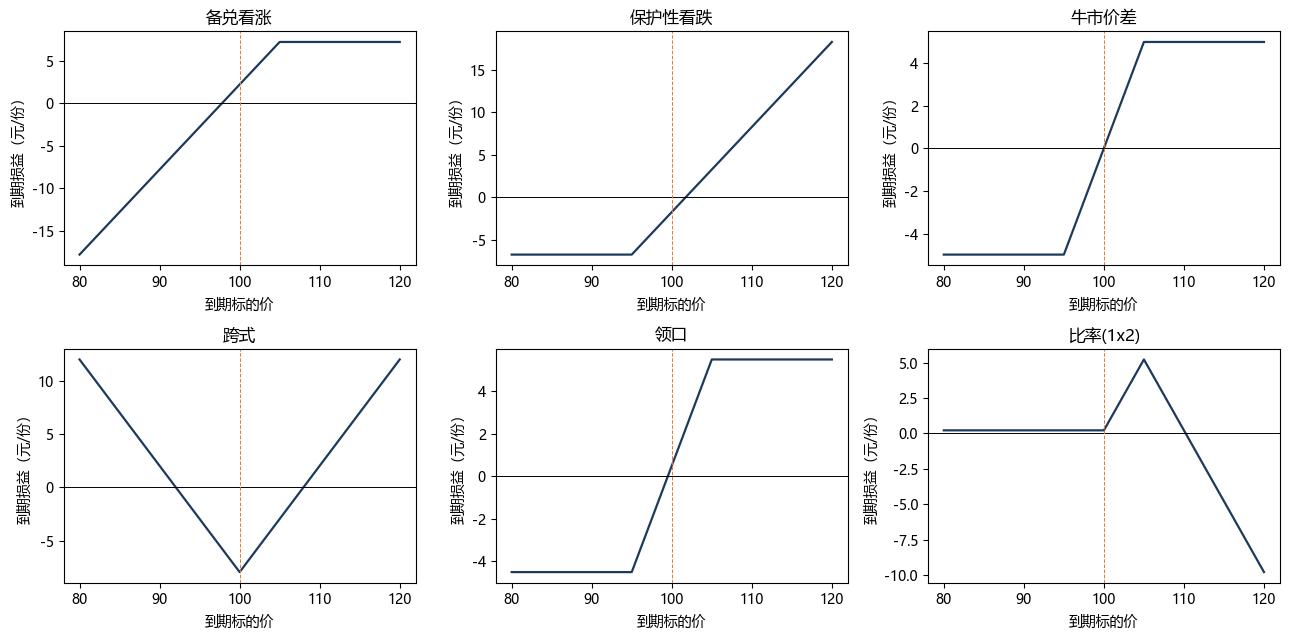

备兑看涨     最大盈利 7.22，最大亏损 -17.78
保护性看跌    最大盈利 18.26，最大亏损 -6.74
牛市价差     最大盈利 5.01，最大亏损 -4.99
跨式       最大盈利 12.03，最大亏损 -7.97
领口       最大盈利 5.48，最大亏损 -4.52
比率(1x2)  最大盈利 5.21，最大亏损 -9.79


In [3]:

grid = np.linspace(80, 120, 161)
c100 = bsm_price(100, 100, 0.25, 0.20, 0.02, "call")
p100 = bsm_price(100, 100, 0.25, 0.20, 0.02, "put")
c95 = bsm_price(100, 95, 0.25, 0.20, 0.02, "call")
c105 = bsm_price(100, 105, 0.25, 0.20, 0.02, "call")
p95 = bsm_price(100, 95, 0.25, 0.20, 0.02, "put")
print("权利金（合成）：c100=%.3f p100=%.3f c95=%.3f c105=%.3f p95=%.3f" % (c100, p100, c95, c105, p95))

payoffs = {
    "备兑看涨": (grid - 100) + c105 - np.maximum(grid - 105, 0),
    "保护性看跌": (grid - 100) + np.maximum(95 - grid, 0) - p95,
    "牛市价差": np.maximum(grid - 95, 0) - np.maximum(grid - 105, 0) - (c95 - c105),
    "跨式": np.maximum(grid - 100, 0) + np.maximum(100 - grid, 0) - (c100 + p100),
    "领口": (grid - 100) + np.maximum(95 - grid, 0) - np.maximum(grid - 105, 0) - p95 + c105,
    "比率(1x2)": np.maximum(grid - 100, 0) - 2 * np.maximum(grid - 105, 0) - (c100 - 2 * c105),
}
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, (name, pnl) in zip(axes.ravel(), payoffs.items()):
    ax.plot(grid, pnl, color="#1B3A5C", linewidth=1.6)
    ax.axhline(0.0, color="black", linewidth=0.7)
    ax.axvline(100.0, color="#E07B39", linewidth=0.7, linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("到期标的价")
    ax.set_ylabel("到期损益（元/份）")
plt.tight_layout()
plt.show()
for name, pnl in payoffs.items():
    print("%-8s 最大盈利 %.2f，最大亏损 %.2f" % (name, pnl.max(), pnl.min()))



**读数与应用**：备兑看涨“收租但封顶”，保护性看跌“付保费但保底”，领口是两者折中；跨式最大盈利在两端、最大亏损在中间；比率策略在标的大涨时亏损放大，**卖方多于买方的结构一定要先算尾部**。常见错误：只画一条腿、忘记权利金、把“到期最大亏损”当成“过程中最大亏损”。

## 3. 进阶：波动率、卖方买方与曲面

### 3.1 波动率：历史、已实现与隐含

- 历史波动率：用过去收益的滚动标准差，例如 20 日收益 × √252；
- 已实现波动率（RV）：某段实际发生的波动；
- 隐含波动率（IV）：把市场期权价反解成 BSM 的 σ，是市场对未来的定价。

IV 高不高，要和 RV、和自己的历史比，而不是看绝对值。**IV 与 RV 的差（VRP）是卖方策略的收益来源，也是买方策略的成本。**

### 3.2 中性卖方与中性买方

Delta 中性不是“没风险”：把 Delta 对冲掉后，组合剩下 Gamma、Vega、Theta。

- **中性卖方**：赚 Theta 与 VRP，怕标的大动（负 Gamma）和波动率飙升（负 Vega）；尾部一次跳空可能吃掉很多天权利金；
- **中性买方**：付 Theta，赚大动（正 Gamma）和波动率上升（正 Vega）；怕横盘、怕 IV 回落。

两类策略赚的是不同的“风险溢价”，没有谁更高级，关键看你能承受哪种尾部。

### 3.3 波动率曲面交易

同一标的、不同行权价/到期日的 IV 构成曲面。常见交易：

1. **水平（整体）**：赌 IV 整体升/降（跨式、宽跨式的 Vega 暴露）；
2. **斜率（偏斜）**：赌虚值 put 与虚值 call 的 IV 差收敛/发散（风险逆转）；
3. **曲率（蝶式）**：赌微笑两翼相对中间的变化；
4. **期限结构**：赌近月与远月 IV 差（日历价差）。

曲面交易的核心是“相对价值”，不是方向。

### 3.4 基差交易

基差 = 现货价 − 期货价（或近月 − 远月）。期权的合成多头/空头可以与期货、现货做相对价值：当期权合成价格与期货价格偏离超过成本，理论上可以做基差收敛。但要注意：**行权/交割规则、资金成本、流动性**都会让“理论基差”不可执行。

### 3.5 情景 PnL：把希腊字母放进一张表

到期 payoff 看不到“过程风险”。情景 PnL 同时动三个变量：标的价格、IV、时间：

$$\Delta \text{PnL}\approx \Delta\cdot\delta S+\frac12\Gamma(\delta S)^2+\text{Vega}\cdot\delta\sigma+\Theta\cdot\delta t.$$

下面用“卖出跨式 + 持仓 7 天”演示：标的价格上下 10%、IV 上下 5 个点，看组合的盈亏分布：



In [4]:

def short_straddle_pnl(ds, div, days):
    S1 = 100.0 * (1 + ds)
    sigma1 = max(0.05, 0.20 + div)
    T1 = max(0.25 - days / 365, 1e-6)
    premium0 = bsm_price(100, 100, 0.25, 0.20, 0.02, "call") + bsm_price(100, 100, 0.25, 0.20, 0.02, "put")
    mark = bsm_price(S1, 100, T1, sigma1, 0.02, "call") + bsm_price(S1, 100, T1, sigma1, 0.02, "put")
    return premium0 - mark


scenario = {}
for ds in [-0.10, -0.05, 0.0, 0.05, 0.10]:
    for div in [-0.05, 0.0, 0.05]:
        scenario[(f"{ds:+.0%}", f"{div:+.0%}")] = round(short_straddle_pnl(ds, div, 7), 3)
scenario_table = pd.Series(scenario).unstack()
scenario_table.index.name = "标的变动"
scenario_table.columns.name = "IV变动"
print("卖出跨式：持有 7 天后的平仓 PnL（元/份，合成示例）")
print(scenario_table.to_string())
print()
print("盈亏平衡（到期、IV 不变）：", round(100 - (bsm_price(100, 100, 0.25, 0.20, 0.02, "call")
      + bsm_price(100, 100, 0.25, 0.20, 0.02, "put")), 2),
      "与", round(100 + (bsm_price(100, 100, 0.25, 0.20, 0.02, "call")
      + bsm_price(100, 100, 0.25, 0.20, 0.02, "put")), 2))


卖出跨式：持有 7 天后的平仓 PnL（元/份，合成示例）
IV变动    +0%    +5%    -5%
标的变动                     
+0%   0.311 -1.597  2.218
+10% -4.046 -5.347 -3.064
+5%  -1.051 -2.781  0.543
-10% -2.954 -4.122 -2.076
-5%  -0.351 -2.044  1.241

盈亏平衡（到期、IV 不变）： 92.03 与 107.97



**读数与应用**：横着看（同一标的变动、不同 IV）：IV 涨，卖方亏；纵着看（同一 IV、不同标的）：标的大动，卖方大亏。**“横盘赚 Theta”只对了一半——IV 一动，Theta 白赚。** 常见错误：情景只动价格不动 IV；忘了时间也在走；用到期 payoff 代替持仓过程。

## 4. 国内期权背景

### 4.1 品种与合约要素

国内常见期权包括 ETF 期权（如上交所/深交所的 50ETF、300ETF 期权）与股指期权（如中金所 IO）。看一张期权合约，至少要关注：

| 要素 | 说明 | 注意 |
|---|---|---|
| 标的 | ETF 或指数 | 与期权到期匹配 |
| 合约单位 | 每张对应多少份/指数点 | 决定一手权利金金额 |
| 行权方式 | 欧式/美式 | 能否提前行权 |
| 到期日 | 到期月某日 | 与期货/现货到期对齐 |
| 行权价间距 | 相邻 K 的距离 | 决定组合精度 |
| 保证金 | 卖方缴纳 | 随标的与波动率变化 |
| 流动性 | 买卖价差与深度 | 虚值/远月常较差 |

> **教学示例，以交易所最新规则为准**：合约单位、行权方式、到期日、保证金公式与行权价间距都随品种和交易所规则变化；本笔记不罗列具体数值，下单前请查交易所与券商的最新公告。

### 4.2 行权、指派与保证金

- 欧式期权只能在到期日行权；美式可提前行权（国内 ETF 期权多为欧式，具体以合约规则为准）；
- 卖方可能被随机指派，被指派后要按 K 买入/卖出标的；
- 卖方保证金不是权利金，是履约保证；标的大涨/波动率上升时保证金可能上调。

### 4.3 流动性与到期日

期权流动性分层明显：平值近月最好，深虚值/远月价差大。到期日越近，Gamma 越大、Theta 越快，**卖方赚得快、亏得也快**。不要把“最后几天的权利金”当成“白捡的钱”。

## 5. 升华：投资观与整体观

### 5.1 期权投资的三层

1. **工具层**：call/put、组合策略、Greeks；
2. **策略层**：方向、波动率、相对价值、增强/保护；
3. **体系层**：研究 → 策略 → 风控 → 执行 → 复盘，形成可重复的流程。

原书强调“体系化”：不是找到一个“神策略”，而是让每笔交易都能被解释、被限额、被复盘。

### 5.2 期权工具化配套权益指数多头

这是原书的核心应用场景：手里有权益多头（指数/ETF），用期权做“增强”或“保护”：

| 目标 | 做法 | 代价 |
|---|---|---|
| 增强收益 | 备兑看涨、现金担保卖 put | 上涨被封顶/下跌要接货 |
| 保护下行 | 保护性看跌、领口 | 付权利金/放弃部分上涨 |
| 降低成本 | 领口（卖 call 补贴 put） | 上涨封顶 |
| 纪律化减仓 | 买 put 替代止损 | 权利金成本 |

### 5.3 整体观：权益 + 期权要算一张敞口表

把现货和期权分成两个账户各算各的，是散户最常见的问题。正确做法是把它们当成**一个组合**，算整体 Delta/Vega，再决定对冲或调整。

### 5.4 卖方风险与买方 theta

下面用一个简化的 ETF 期权教学示例（S=3.00 元、合约单位 10,000 份/张——**教学示例，以交易所最新规则为准**）看两件事：卖方一张合约的尾部风险有多大、买方的时间价值衰减有多快。



卖出 1 张平值 put（教学示例：S=3.00，K=3.00，sigma=20%，T=0.25）
权利金/张: 1120 元 | 最大亏损/张: 28880 元 | 简化保证金估算/张: 4500 元
账户风险预算 10% = 20000 元 -> 按最大亏损最多可卖 0 张


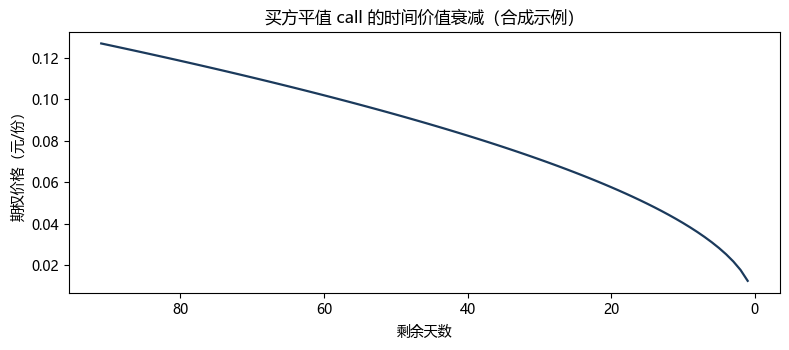

剩余 90 天价格 0.1268 -> 剩余 1 天价格 0.0126


In [5]:

S_etf, K_put = 3.00, 3.00
put_prem = bsm_price(S_etf, K_put, 0.25, 0.20, 0.02, "put")
contract = 10_000
premium_cash = put_prem * contract
max_loss = (K_put - put_prem) * contract
margin_est = 0.15 * S_etf * contract
risk_capital = 200_000
risk_budget = 0.10 * risk_capital
lots = int(risk_budget / max_loss)
print("卖出 1 张平值 put（教学示例：S=3.00，K=3.00，sigma=20%，T=0.25）")
print("权利金/张: %.0f 元 | 最大亏损/张: %.0f 元 | 简化保证金估算/张: %.0f 元"
      % (premium_cash, max_loss, margin_est))
print("账户风险预算 10%% = %.0f 元 -> 按最大亏损最多可卖 %d 张" % (risk_budget, lots))

days_left = np.arange(1, 92)
call_values = [bsm_price(3.00, 3.00, d / 365, 0.20, 0.02, "call") for d in days_left]
plt.figure(figsize=(8, 3.6))
plt.plot(days_left, call_values, color="#1B3A5C", linewidth=1.6)
plt.gca().invert_xaxis()
plt.title("买方平值 call 的时间价值衰减（合成示例）")
plt.xlabel("剩余天数")
plt.ylabel("期权价格（元/份）")
plt.tight_layout()
plt.show()
print("剩余 90 天价格 %.4f -> 剩余 1 天价格 %.4f" % (call_values[-1], call_values[0]))



**读数与应用**：卖方收的权利金 1,120 元，但一张合约的最大亏损约 28,880 元——**收租的收益和尾部风险差了一个数量级**；按 2 万元（10%）的风险预算，连一张都卖不了。保证金估算只有 4,500 元，比最大损失小得多：**保证金不是最大损失，它只保证“当下不被强平”**。买方则相反：剩余 90 天权利金 0.127 元，最后一天只剩 0.013 元，时间价值加速归零。常见错误：卖方只算权利金收益率不算最大亏损；买方用“方向会涨”掩盖 theta 成本；把保证金当成最大风险。

## 6. 对一人量化的用法

1. **先画 payoff/风险图，再谈方向**：画不出最大亏损与盈亏平衡，就不下单；
2. **卖方先算尾部**：一张合约最坏亏多少、账户能承受几张、跳空后保证金够不够；
3. **买方先算 theta/IV**：方向对了但幅度不够，会被时间价值吃掉；IV 高位买期权性价比低；
4. **权益 + 期权算整体敞口**：现货与期权放在同一张表里算 Delta/Vega，不做“两张皮”。

最后把现货与期权放在一起，算整体敞口：



In [6]:

S_etf = 3.00
contract = 10_000
spot_units = 100_000
put = bsm_greeks(S_etf, 3.00, 0.25, 0.20, 0.02, "put")
call = bsm_greeks(S_etf, 3.15, 0.25, 0.20, 0.02, "call")
lots = 3


def portfolio_exposure(name, delta_units, vega_cash):
    return {"组合": name, "Delta(份)": round(delta_units, 0), "Vega(元/1%IV)": round(vega_cash, 0)}


rows = [
    portfolio_exposure("仅现货", spot_units, 0.0),
    portfolio_exposure("现货+3张保护性看跌", spot_units + lots * put[0] * contract,
                       lots * put[2] * contract / 100),
    portfolio_exposure("现货+3张备兑看涨", spot_units - lots * call[0] * contract,
                       -lots * call[2] * contract / 100),
    portfolio_exposure("现货+领口(3张put+3张call)", spot_units + lots * put[0] * contract - lots * call[0] * contract,
                       lots * put[2] * contract / 100 - lots * call[2] * contract / 100),
]
exposure = pd.DataFrame(rows)
print("权益 30 万元 + ETF 期权组合的整体敞口（合成示例）")
print(exposure.to_string(index=False))
print()
print("读法：Delta 是“等效持有多少份 ETF”；Vega 是 IV 每变化 1 个点，组合大约变多少元。")


权益 30 万元 + ETF 期权组合的整体敞口（合成示例）
                 组合  Delta(份)  Vega(元/1%IV)
                仅现货  100000.0           0.0
         现货+3张保护性看跌   86195.0         179.0
          现货+3张备兑看涨   89529.0        -167.0
现货+领口(3张put+3张call)   75724.0          12.0

读法：Delta 是“等效持有多少份 ETF”；Vega 是 IV 每变化 1 个点，组合大约变多少元。



**读数与应用**：保护性看跌把 Delta 降下来、Vega 变成正（IV 涨对保护有利）；备兑看涨降低 Delta、Vega 为负；领口是两者折中。**“保护”不是免费的：付出的权利金与放弃的上涨，都要在整体敞口表里看得见。**

## 本章小结

### 一张表

| 主题 | 核心问题 | 关键工具 |
|---|---|---|
| 期权基础 | 买方/卖方权利义务 | call/put、内在价值、时间价值 |
| 风险度量 | 各变量一动会怎样 | Delta/Gamma/Vega/Theta |
| 风险管理 | 最坏亏多少 | 最大损失、仓位、保证金、压力测试 |
| 基础策略 | 观点怎么表达 | 备兑、保护、价差、跨式、领口、比率 |
| 进阶 | 赚什么风险溢价 | 波动率、中性卖方/买方、曲面、基差 |
| 升华 | 期权如何融入权益 | 增强/保护、整体敞口 |
| 国内实务 | 合约与流动性 | 合约单位、行权、保证金、到期日 |

### 八句话

1. 买方风险有限，但敌人是时间和波动率。
2. 卖方收益有限，尾部风险可能无限。
3. 先画 payoff/风险图，再谈方向。
4. 卖方先算最大亏损，再算权利金收益率。
5. 买方先算 theta 与 IV，再谈“会涨”。
6. Delta 中性不等于没有风险。
7. 权益和期权要算同一张敞口表。
8. 国内参数是教学示例，下单前查交易所最新规则。

## 本章习题

**1.** 买 call 与卖 call 的最大盈利、最大亏损分别是什么？

**2.** 期权价格由哪两部分组成？平值期权的时间价值为什么最大？

**3.** 买方和卖方的 Gamma、Vega、Theta 符号为什么相反？

**4.** 备兑看涨与保护性看跌分别适合什么观点？各自的代价是什么？

**5.** 卖出跨式在标的大涨或大跌时为什么会亏？

**6.** 中性卖方策略赚什么钱、最怕什么？

**7.** 国内 ETF 期权的合约单位、行权方式、到期日、保证金应该以什么为准？

**8.** 为什么“权益 + 期权”要算整体 Delta/Vega，而不是分开算？

<details><summary>参考答案</summary>

**1.** 买 call：最大盈利无限、最大亏损为权利金；卖 call：最大盈利为权利金、最大亏损理论上无限。

**2.** 内在价值 + 时间价值；平值时期权最“犹豫”，上涨和下跌都可能让它变实值，所以时间价值最大。

**3.** 因为买卖方向相反，同一头寸取反后，正负号全部取反：买方正 Gamma/Vega、负 Theta，卖方相反。

**4.** 备兑看涨适合温和看涨/震荡收租，代价是上涨被封顶；保护性看跌适合“保留上涨、防大跌”，代价是付权利金。

**5.** 卖出跨式是负 Gamma：标的大动时，一边的亏损快速放大，可能超过两份权利金。

**6.** 赚 Theta 与波动率风险溢价（VRP）；最怕标的大幅波动（负 Gamma）与波动率飙升（负 Vega），以及跳空导致的尾部亏损。

**7.** 以交易所与券商的最新规则/公告为准；本笔记中的数值都是教学示例，不构成交易依据。

**8.** 因为期权的 Delta/Vega 会改变现货的风险暴露；只看现货会把“保护”或“增强”当成免费的，整体敞口表才能算出真实的方向与波动率风险。

</details>

---

## 参考资料

- 沈发鹏：《期权投资盈利之道：期权策略的“体系化”运用，权益配合的“方法论”实践》。
- Hull, J. C. *Options, Futures, and Other Derivatives*（BSM、Greeks、组合策略）。
- 第 24–28 章：期权定价、希腊字母、隐含波动率曲面、动态对冲、价差组合。
- 交易所与券商关于 ETF/股指期权合约、行权、保证金的最新规则公告（**教学示例，以最新规则为准**）。
